# Mission 03 — Multi-Head Attention, RoPE & GQA KV-Cache
**Squadron Colby** · USSE Noosphere · Sector SEC-03-M45 (Pleiades)

This notebook runs the four deliverables in order and shows their results. Every part is also a standalone script (`python 0X_....py`). CPU is enough.

In [1]:
import importlib.util, pathlib, sys
from IPython.display import Image, display
ROOT = pathlib.Path.cwd()
def load(name, file):
    spec = importlib.util.spec_from_file_location(name, ROOT / file)
    mod = importlib.util.module_from_spec(spec); sys.modules[name] = mod; spec.loader.exec_module(mod)
    return mod
mha  = load("mha",  "01_MultiHead_Attention_Core.py")
rope = load("rope", "02_RoPE_Positional_Engine.py")
gqa  = load("gqa",  "03_GQA_and_KVCache_Benchmark.py")
dos  = load("dos",  "04_kv_dos_simulation.py")

## Part 1 · Systems Architect — Multi-Head Self-Attention from scratch
$\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}+M\right)V$, with learned $W_Q, W_K, W_V, W_O$, head splitting `(B, N, h, d) → (B, h, N, d)` and a lower-triangular causal mask $M$.

In [2]:
mha.main()

USSE NOOSPHERE · SUBSYSTEM 03 · PART 1: MULTI-HEAD SELF-ATTENTION

=== Subsystem 03 · Variance preservation test (q, k ~ N(0,1)) ===
  d_k |   Var(q·k) | expected |  Var(q·k/√d_k) | result
----------------------------------------------------------
   16 |      16.31 |       16 |         1.0195 | PASS
   32 |      32.14 |       32 |         1.0044 | PASS
   64 |      64.18 |       64 |         1.0027 | PASS
  128 |     128.13 |      128 |         1.0010 | PASS
  256 |     255.96 |      256 |         0.9998 | PASS
  512 |     511.99 |      512 |         1.0000 | PASS
[PASS] Scaling by 1/sqrt(d_k) keeps Var ≈ 1 for every head size.

=== What happens WITHOUT scaling: softmax saturation ===
  d_k | max weight (scaled) | max weight (unscaled) | ‖J‖ scaled | ‖J‖ unscaled
----------------------------------------------------------------------------------
   16 |               0.069 |                 0.533 |     0.1351 |       0.2943


   64 |               0.069 |                 0.769 |     0.1373 |       0.2010
  256 |               0.069 |                 0.888 |     0.1359 |       0.1335


  512 |               0.068 |                 0.921 |     0.1363 |       0.0919
Scaled: the softmax behaves the same for every d_k. Unscaled: scores grow like sqrt(d_k),
the softmax drifts towards one-hot and its Jacobian (the gradient path) keeps shrinking.

=== Causal mask check ===
max attention weight above diagonal: 0.0e+00  ·  outputs 0-6 unchanged after editing tokens 7-9: True
[PASS] No information flows from future tokens.

=== Forward pass ===
input (2, 16, 256) -> output (2, 16, 256) · attention (2, 4, 16, 16) · rows sum to 1: True
parameters: 4 × d_model² = 262,144



Figures written to figures/01_variance_scaling.png, figures/01_softmax_saturation.png

[OK] Subsystem 03 attention mesh online.


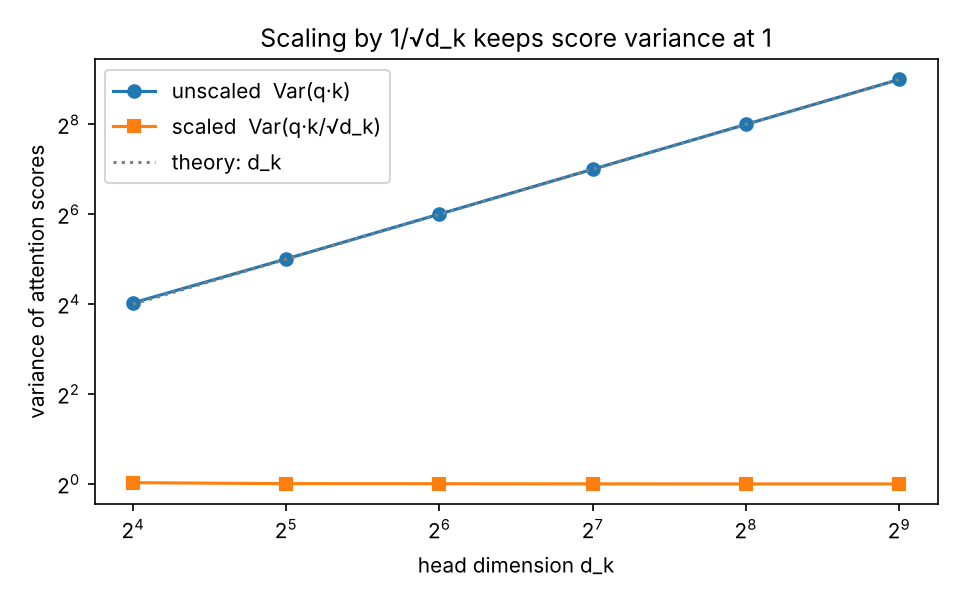

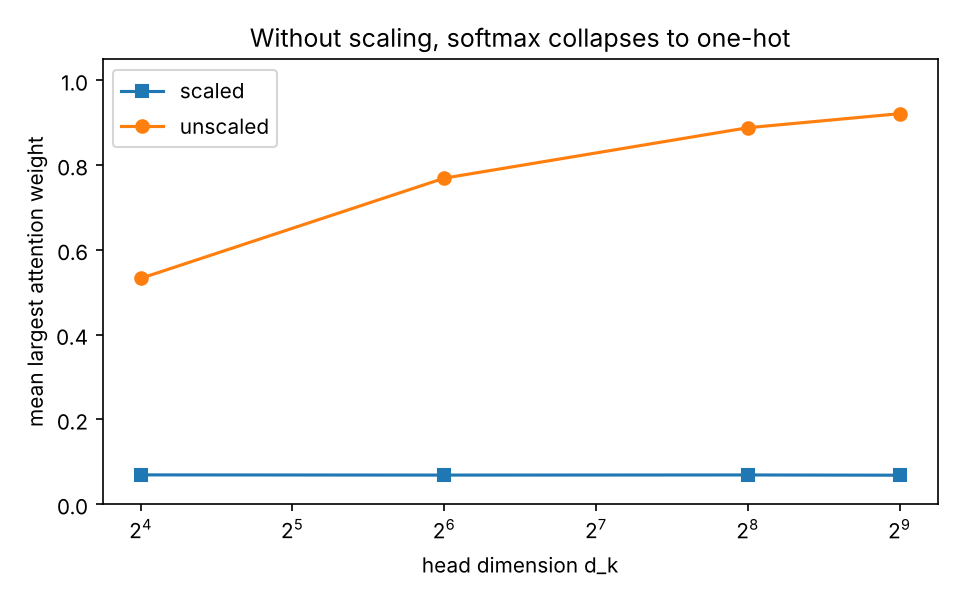

In [3]:
display(Image("figures/01_variance_scaling.png", width=520)); display(Image("figures/01_softmax_saturation.png", width=520))

## Part 2 · Communications & Protocol Officer — RoPE engine
Each pair of dimensions is rotated by $m\,\theta_i$ with $\theta_i = 10000^{-2(i-1)/d}$. The score then depends only on the distance $m-n$.

In [4]:
rope.main()

USSE NOOSPHERE · SUBSYSTEM 03 · PART 2: ROTARY POSITIONAL EMBEDDINGS

=== Verification ===
norm preserved under rotation: max |‖RoPE(x)‖ − ‖x‖| = 9.54e-07
<RoPE(q,10), RoPE(k,25)> = 10.773232   <RoPE(q,50), RoPE(k,65)> = 10.773232   |diff| = 8.65e-08
relative invariance over 200 random (q, k, m, n, δ): max relative error = 1.74e-06
batched (B, h, N, d) = (2, 8, 16, 64) -> (2, 8, 16, 64)
[PASS] RoPE is a pure rotation and the score depends only on m − n.

=== RoPE vs ALiBi: position-only score by distance ===
     Δ | RoPE s(Δ) | ALiBi bias (slope 0.125)
     0 |     1.000 |                  -0.00
     1 |     0.970 |                  -0.12
     4 |     0.759 |                  -0.50
    16 |     0.620 |                  -2.00
    64 |     0.477 |                  -8.00
   256 |     0.321 |                 -32.00
  1024 |     0.204 |                -128.00
  4096 |    -0.053 |                -512.00
RoPE decays smoothly and stays bounded (|s| ≤ 1); ALiBi keeps falling linearly forever,


Figures written to figures/02_rope_vs_alibi_decay.png, figures/02_attention_heatmaps.png

[OK] Positional engine online.


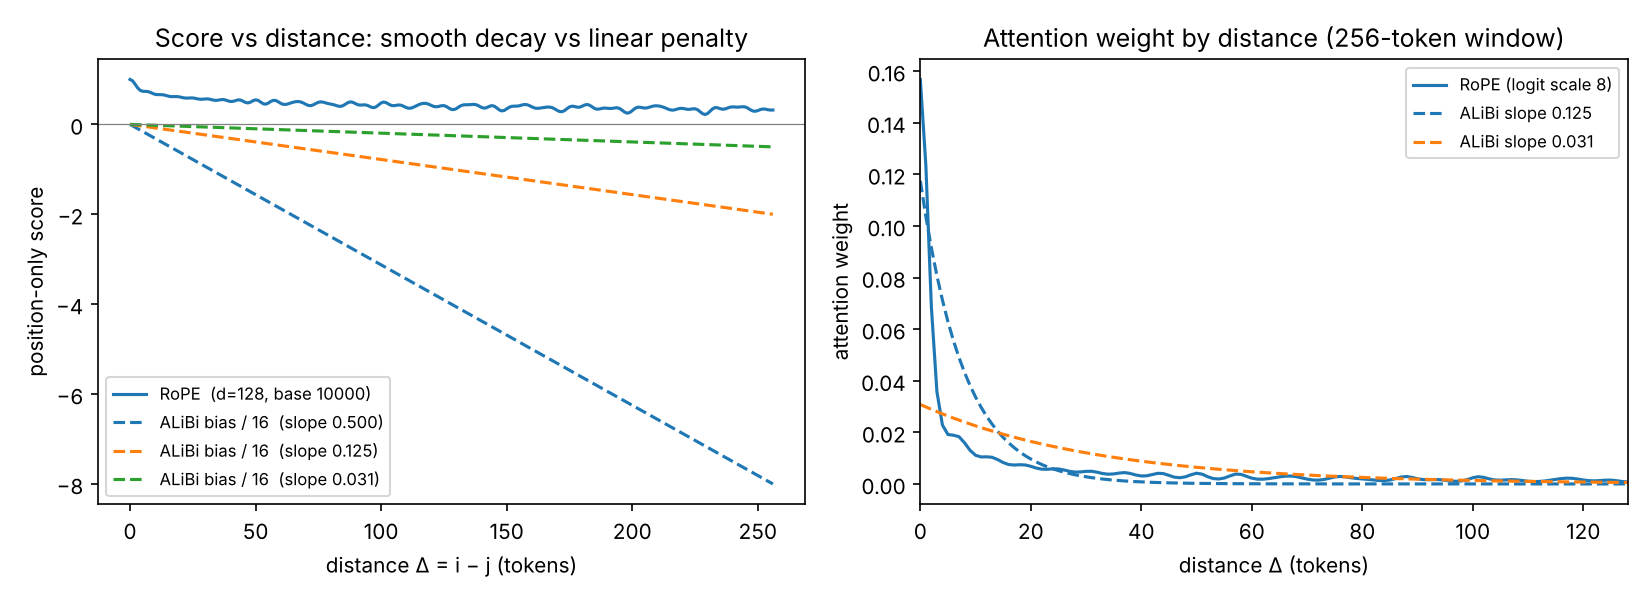

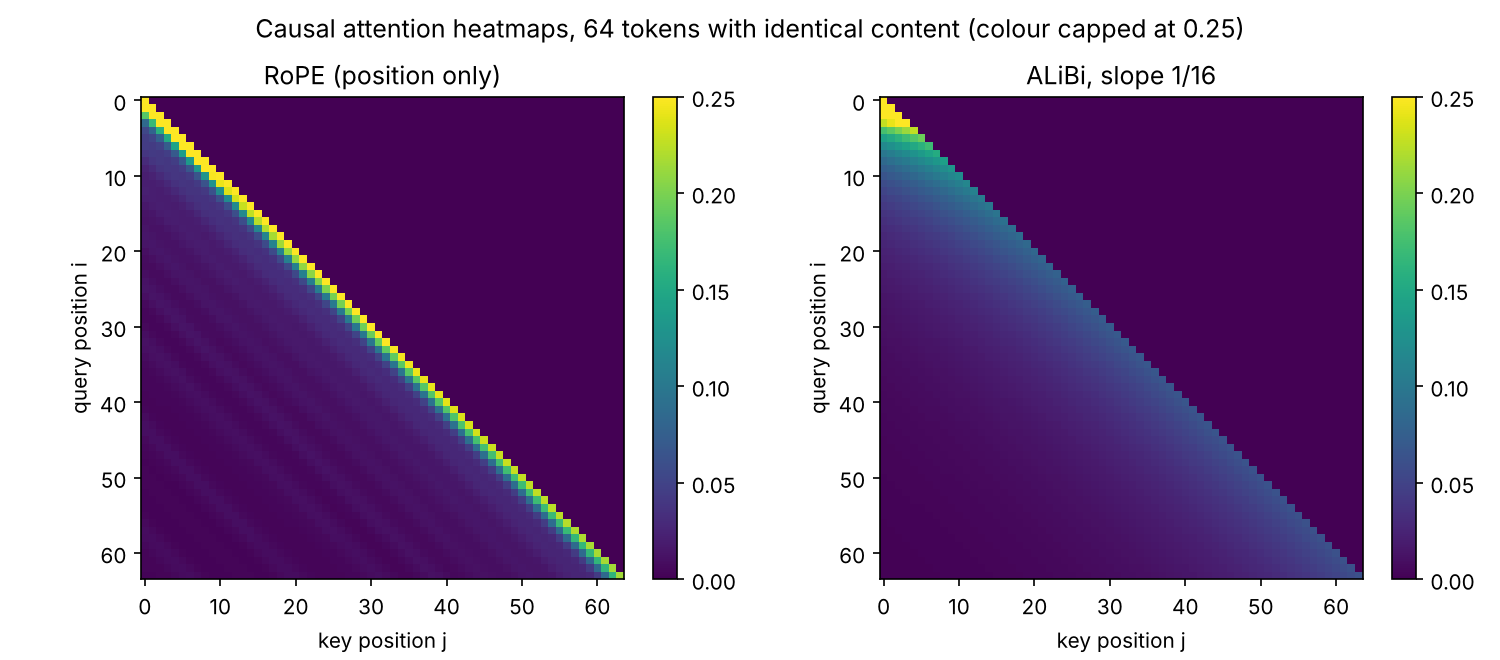

In [5]:
display(Image("figures/02_rope_vs_alibi_decay.png", width=820)); display(Image("figures/02_attention_heatmaps.png", width=760))

## Part 3 · Data & Payload Specialist — GQA & KV-cache benchmark
MHA (32:32) vs GQA (32:8) vs MQA (32:1) on a LLaMA-3-8B-shaped model. `--quick` mode here keeps the notebook fast; run the script for the full timing table.

In [6]:
import sys; sys.argv = ['03', '--quick']
gqa.main()

USSE NOOSPHERE · SUBSYSTEM 03 · PART 3: GQA & KV-CACHE

=== Correctness ===
cached token-by-token decoding vs full causal pass: max |diff| = 4.77e-07
GQA grouped view vs repeat_interleave:              max |diff| = 0.00e+00
GQA with H_kv = H_q vs Part 1 MultiHeadSelfAttention: max |diff| = 1.79e-07
[PASS] KV-cache and GQA are exact.



=== Why cache? Generating 256 tokens with one layer (CPU) ===
recompute prefix every step: 395 ms   ·   with KV-cache: 57 ms   ·   7.0× faster

=== Benchmark: MHA vs GQA vs MQA ===


KV-cache for a LLaMA-3-8B-shaped model (32 layers, 32 query heads, d_head 128, fp16, batch 1)
Variant          |      N |   KV-cache | BW @50 tok/s | H100 KV read | CPU attn step
                 |        |       (MB) |       (GB/s) |   (ms/token) |    (ms/layer)
------------------------------------------------------------------------------------
MHA (32:32)      |   1024 |        512 |         26.8 |        0.160 |         14.87
MHA (32:32)      |   4096 |      2,048 |        107.4 |        0.641 |         18.33
MHA (32:32)      |  16384 |      8,192 |        429.5 |        2.564 |             —
MHA (32:32)      |  32768 |     16,384 |        859.0 |        5.128 |             —
GQA (32:8, 4:1)  |   1024 |        128 |          6.7 |        0.040 |          9.17
GQA (32:8, 4:1)  |   4096 |        512 |         26.8 |        0.160 |          9.43
GQA (32:8, 4:1)  |  16384 |      2,048 |        107.4 |        0.641 |             —
GQA (32:8, 4:1)  |  32768 |      4,096 |        214.7 | 

Figure written to figures/03_kv_cache_memory.png

[OK] KV-cache transceiver online.


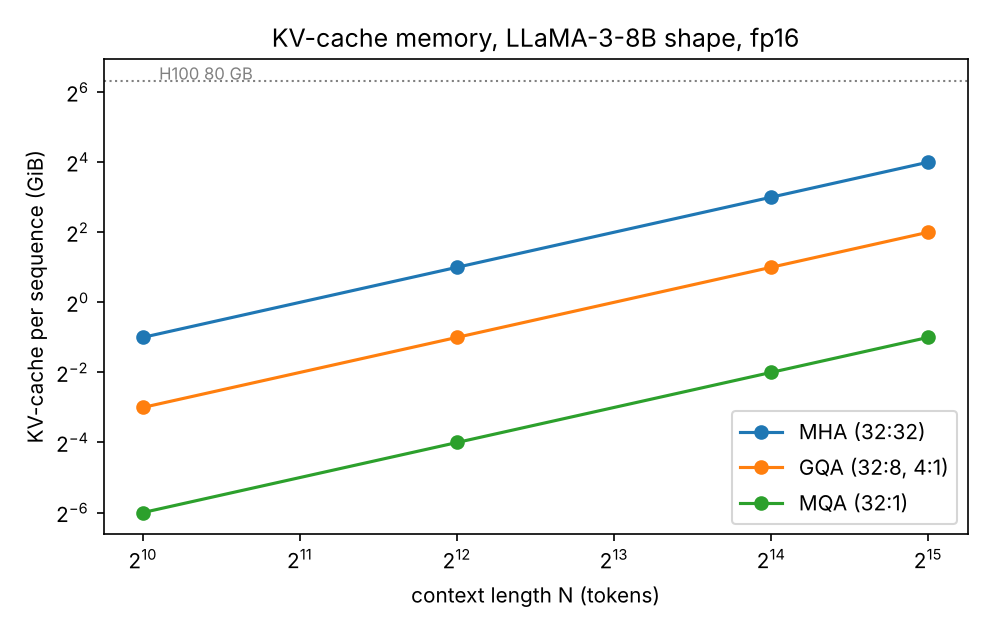

In [7]:
display(Image("figures/03_kv_cache_memory.png", width=560))

## Part 4 · Security & Ethics Sentinel — FlashAttention IO & KV-cache DoS
Full write-up: `04_Memory_Hierarchy_and_Safety_Audit.md`.

In [8]:
dos.main()

USSE NOOSPHERE · SUBSYSTEM 03 · PART 4: MEMORY HIERARCHY & DoS AUDIT

=== FlashAttention IO (elements moved HBM <-> SRAM, one head, M ≈ 100K elements) ===
      N | standard, d=128 | flash, d=128 |     × | standard, d=64 | flash, d=64 |     ×
   1024 |        4.72e+06 |     2.10e+06 |  2.2× |       4.46e+06 |    6.55e+05 |  6.8×
   4096 |        6.92e+07 |     2.52e+07 |  2.8× |       6.82e+07 |    6.82e+06 | 10.0×
   8192 |        2.73e+08 |     9.44e+07 |  2.9× |       2.71e+08 |    2.52e+07 | 10.8×
  16384 |        1.08e+09 |     3.65e+08 |  3.0× |       1.08e+09 |    9.44e+07 | 11.4×
  32768 |        4.31e+09 |     1.43e+09 |  3.0× |       4.30e+09 |    3.65e+08 | 11.8×
  65536 |        1.72e+10 |     5.69e+09 |  3.0× |       1.72e+10 |    1.43e+09 | 12.0×
(the N×N score matrix alone at N=8192 is 128 MiB per head; ×32 heads = 4 GiB written and read back per layer by standard attention)

=== KV-cache DoS on one H100 80 GB serving LLaMA-3-8B ===
free for KV-cache: 74.5 GiB − weights 

Figure written to figures/04_dos_oom.png


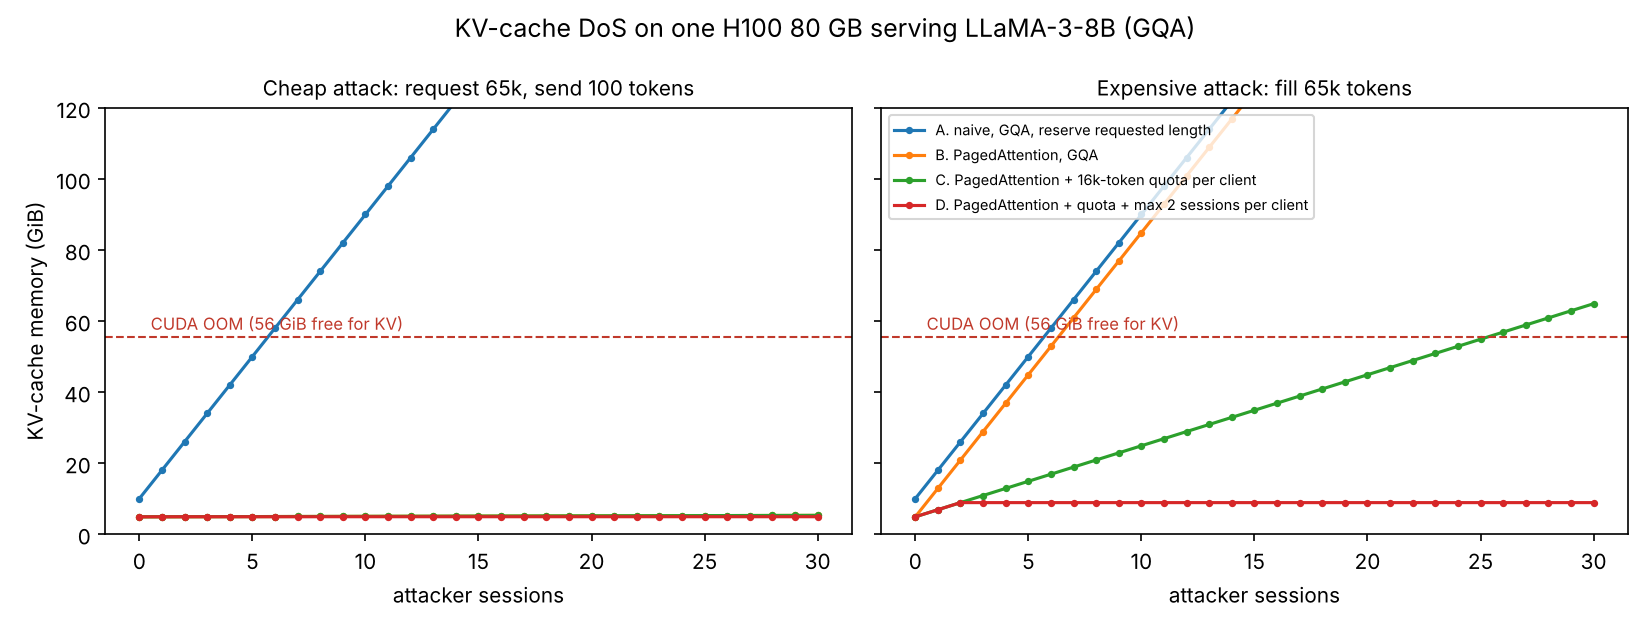

In [9]:
display(Image("figures/04_dos_oom.png", width=860))

## Summary
| Part | Result |
|---|---|
| 1 | scaling by $1/\sqrt{d_k}$ keeps score variance ≈ 1 for every head size; causal mask verified |
| 2 | RoPE is a pure rotation; scores depend only on $m-n$ (max error ~1e-6) |
| 3 | KV-cache decoding is exact and much faster than recomputation; GQA 4:1 cuts the cache by 75% |
| 4 | a naive server crashes at the 6th malicious session; PagedAttention + quotas + session caps survive |